# 02 · OpenCV e espaços de cor

**Ementa 02** · Neste notebook você vai dominar as operações da OpenCV que usaremos no resto do módulo e descobrir
**qual canal/espaço de cor revela melhor cada estrutura da retina** — com medidas, não só com a impressão visual.

1. armadilhas clássicas da OpenCV (BGR × RGB, caminhos com acento, estouro de `uint8`);
2. operações essenciais: redimensionar, recortar, espelhar, desenhar;
3. **por que o canal verde?** — contraste dos vasos em cada canal, medido contra a segmentação manual do HRF;
4. HSV, LAB, YCrCb e quando usar cada um;
5. a **cor muda com a câmera** — e por que isso importa para a IA;
6. máscara do **campo de visão (FOV)** passo a passo.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retina_pdi import dados, pipeline as P, visualizacao as V

V.configurar_estilo()
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")

OpenCV 4.14.0 | NumPy 2.5.3 | pandas 3.0.6


## 1. OpenCV: o básico e as armadilhas

### 1.1 Caminhos com acento (Windows)
`cv2.imread` costuma falhar (devolve `None`, **sem erro**) quando o caminho tem caracteres não-ASCII — como `Módulo 2`.
A alternativa robusta é ler os bytes com NumPy e decodificar com `cv2.imdecode` — é o que `dados.carregar_rgb` faz.

In [2]:
caminho = dados.RAIZ / dados.selecionar("normal", "hrf").iloc[0].arquivo
print("caminho:", caminho)

via_imread = cv2.imread(str(caminho))
print("cv2.imread  →", None if via_imread is None else via_imread.shape, "(None = falhou em silêncio)")

bgr = cv2.imdecode(np.fromfile(str(caminho), np.uint8), cv2.IMREAD_COLOR)
print("cv2.imdecode →", bgr.shape)

caminho: C:\Users\Tiago Lima\OneDrive\Projetos\Editais\Aprovados\COMPET\Fase 1\Módulo 2\data\raw\hrf\images\01_h.jpg
cv2.imread  → None (None = falhou em silêncio)
cv2.imdecode → (2336, 3504, 3)


### 1.2 BGR × RGB
A OpenCV guarda os canais na ordem **B, G, R**; Matplotlib, PIL e TensorFlow esperam **R, G, B**. Misturar os dois não dá erro — só cores erradas (e modelos treinados com a ordem trocada).

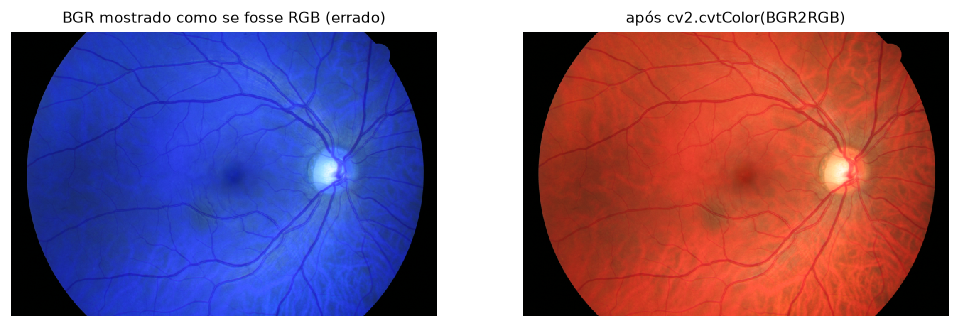

igualdade com o carregador do projeto: True


In [3]:
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)          # conversão correta (equivale a bgr[..., ::-1])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].imshow(dados.reduzir(bgr, 600)); axs[0].set_title("BGR mostrado como se fosse RGB (errado)")
axs[1].imshow(dados.reduzir(rgb, 600)); axs[1].set_title("após cv2.cvtColor(BGR2RGB)")
for a in axs: a.axis("off")
plt.show()
print("igualdade com o carregador do projeto:", np.array_equal(rgb, dados.carregar_rgb(caminho)))

### 1.3 Estouro de `uint8`
Com `uint8` o valor máximo é 255. A soma do NumPy **dá a volta** (módulo 256); a `cv2.add` **satura** em 255. Numa retinografia, isso transforma o disco óptico (claro) em preto:

np.uint8(200) + np.uint8(100) = 44    (deu a volta: 300 − 256)
cv2.add(200, 100)             = 255   (saturou em 255)


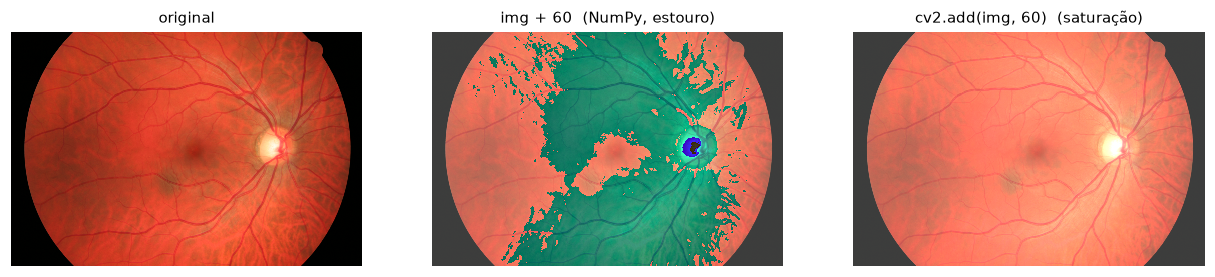

In [4]:
with np.errstate(over="ignore"):
    print("np.uint8(200) + np.uint8(100) =", np.uint8(200) + np.uint8(100), "   (deu a volta: 300 − 256)")
print("cv2.add(200, 100)             =", int(cv2.add(np.uint8([[200]]), np.uint8([[100]]))[0, 0]), "  (saturou em 255)")

pequena = dados.reduzir(rgb, 700)
errada = pequena + np.uint8(60)                 # NumPy: dá a volta nos pixels claros
certa = cv2.add(pequena, (60, 60, 60, 0))       # OpenCV: satura
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, im, t in zip(axs, [pequena, errada, certa], ["original", "img + 60  (NumPy, estouro)", "cv2.add(img, 60)  (saturação)"]):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
plt.show()

> **Regra:** para fazer contas, converta para `float32` (`img.astype(np.float32)`), calcule e só no final volte a `uint8` com `np.clip(x, 0, 255).astype(np.uint8)`.
> É o que todas as funções do módulo `retina_pdi.pipeline` fazem.

## 2. Operações essenciais

### 2.1 Redimensionar — a interpolação importa
Ao **reduzir**, `INTER_AREA` (média de área) evita *aliasing*; `INTER_NEAREST` e `INTER_LINEAR` "pulam" pixels e criam serrilhados e vasos quebrados.
Ao **ampliar**, `INTER_CUBIC` e `INTER_LANCZOS4` preservam melhor a suavidade. Reduzimos 1/8 uma imagem de 3504 px e olhamos os vasos finos:

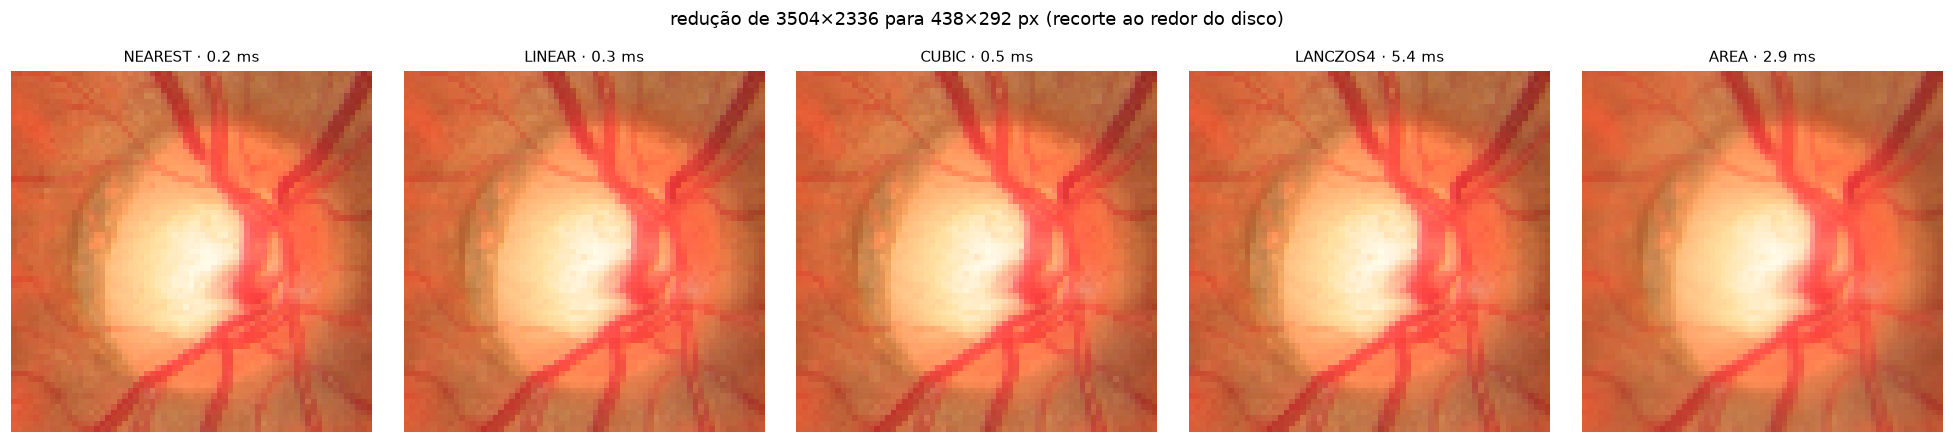

In [5]:
import time
grande = dados.carregar_rgb(dados.selecionar("normal", "hrf").iloc[0].arquivo)
alvo = (grande.shape[1] // 8, grande.shape[0] // 8)
metodos = {"NEAREST": cv2.INTER_NEAREST, "LINEAR": cv2.INTER_LINEAR, "CUBIC": cv2.INTER_CUBIC,
           "LANCZOS4": cv2.INTER_LANCZOS4, "AREA": cv2.INTER_AREA}
d0 = P.localizar_disco_optico(dados.reduzir(grande, 512))
cy, cx = (int(v * grande.shape[1] / 512) for v in d0.centro)          # região dos vasos, perto do disco
janela = (slice(max(cy - 260, 0), cy + 260), slice(max(cx - 260, 0), cx + 260))

fig, axs = plt.subplots(1, len(metodos), figsize=(3.6 * len(metodos), 3.9))
linhas = []
for ax, (nome, flag) in zip(axs, metodos.items()):
    t0 = time.perf_counter(); pq = cv2.resize(grande, alvo, interpolation=flag); dt = (time.perf_counter() - t0) * 1e3
    y0_, y1_, x0_, x1_ = (janela[0].start // 8, janela[0].stop // 8, janela[1].start // 8, janela[1].stop // 8)
    ax.imshow(cv2.resize(pq[y0_:y1_, x0_:x1_], (390, 390), interpolation=cv2.INTER_NEAREST)); ax.axis("off"); ax.set_title(f"{nome} · {dt:.1f} ms")
plt.suptitle(f"redução de {grande.shape[1]}×{grande.shape[0]} para {alvo[0]}×{alvo[1]} px (recorte ao redor do disco)", y=1.02)
fig.tight_layout(); plt.show()

O notebook 06 mede esse efeito **quantitativamente** (contraste dos vasos após a redução) e explica por que `INTER_AREA` é a escolha padrão do pipeline.

### 2.2 Recortar, espelhar, girar, desenhar

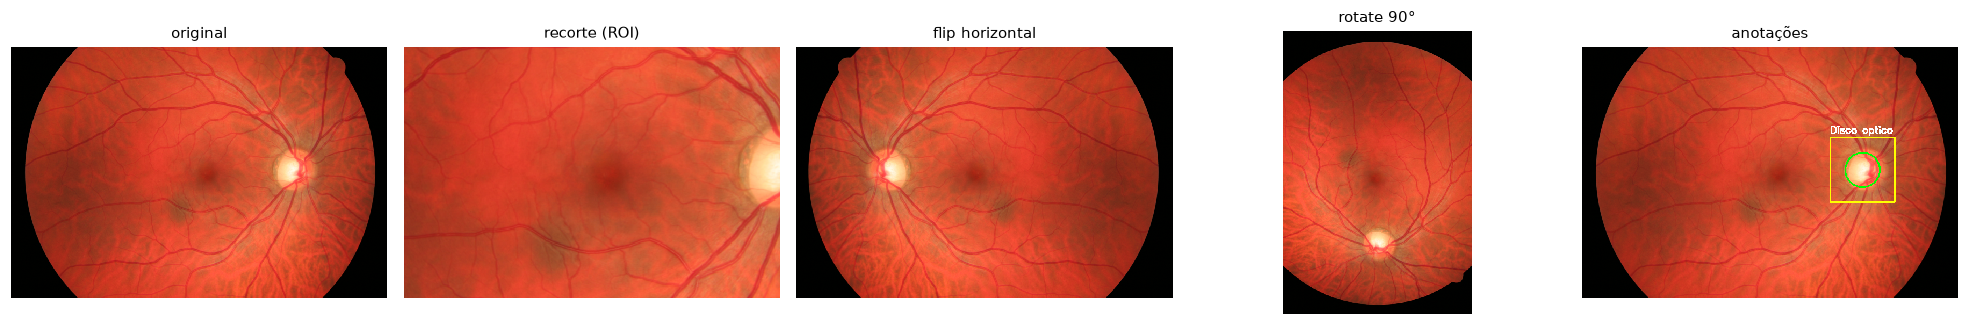

In [6]:
img = dados.reduzir(rgb, 700).copy()
h, w = img.shape[:2]

recorte = img[h // 4: 3 * h // 4, w // 4: 3 * w // 4]         # slicing = ROI (uma view!)
espelhada = cv2.flip(img, 1)                                     # 1 = horizontal (olho direito ↔ esquerdo)
girada = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

anot = img.copy()
d = P.localizar_disco_optico(img)
cv2.circle(anot, (int(d.centro[1]), int(d.centro[0])), int(d.raio), (0, 255, 0), 2)      # cv2 usa (x, y)!
cv2.rectangle(anot, (int(d.centro[1]) - 60, int(d.centro[0]) - 60), (int(d.centro[1]) + 60, int(d.centro[0]) + 60), (255, 255, 0), 2)
cv2.putText(anot, "Disco optico", (int(d.centro[1]) - 60, int(d.centro[0]) - 68), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)

V.grade([img, recorte, espelhada, girada, anot], ["original", "recorte (ROI)", "flip horizontal", "rotate 90°", "anotações"], colunas=5, largura=3.6)
plt.show()

Três armadilhas de coordenadas: **(1)** o NumPy indexa `img[y, x]`; a OpenCV desenha e redimensiona com `(x, y)` / `(largura, altura)`.
**(2)** `cv2.putText` só desenha ASCII (sem acentos) — por isso "Disco optico" acima. **(3)** desenhe sempre numa *cópia*, senão você altera a imagem original.
Espelhar é útil para padronizar **olho direito × esquerdo** (o disco óptico fica à direita ou à esquerda da mácula).

## 3. Canais de cor: por que o canal verde?

Cada canal enxerga a retina de um jeito: a **hemoglobina** (sangue) absorve muito o verde → **vasos escuros** no canal verde;
a luz vermelha penetra até a coroide, saturando a imagem; o azul é fraco e ruidoso. Veja em três câmeras diferentes:

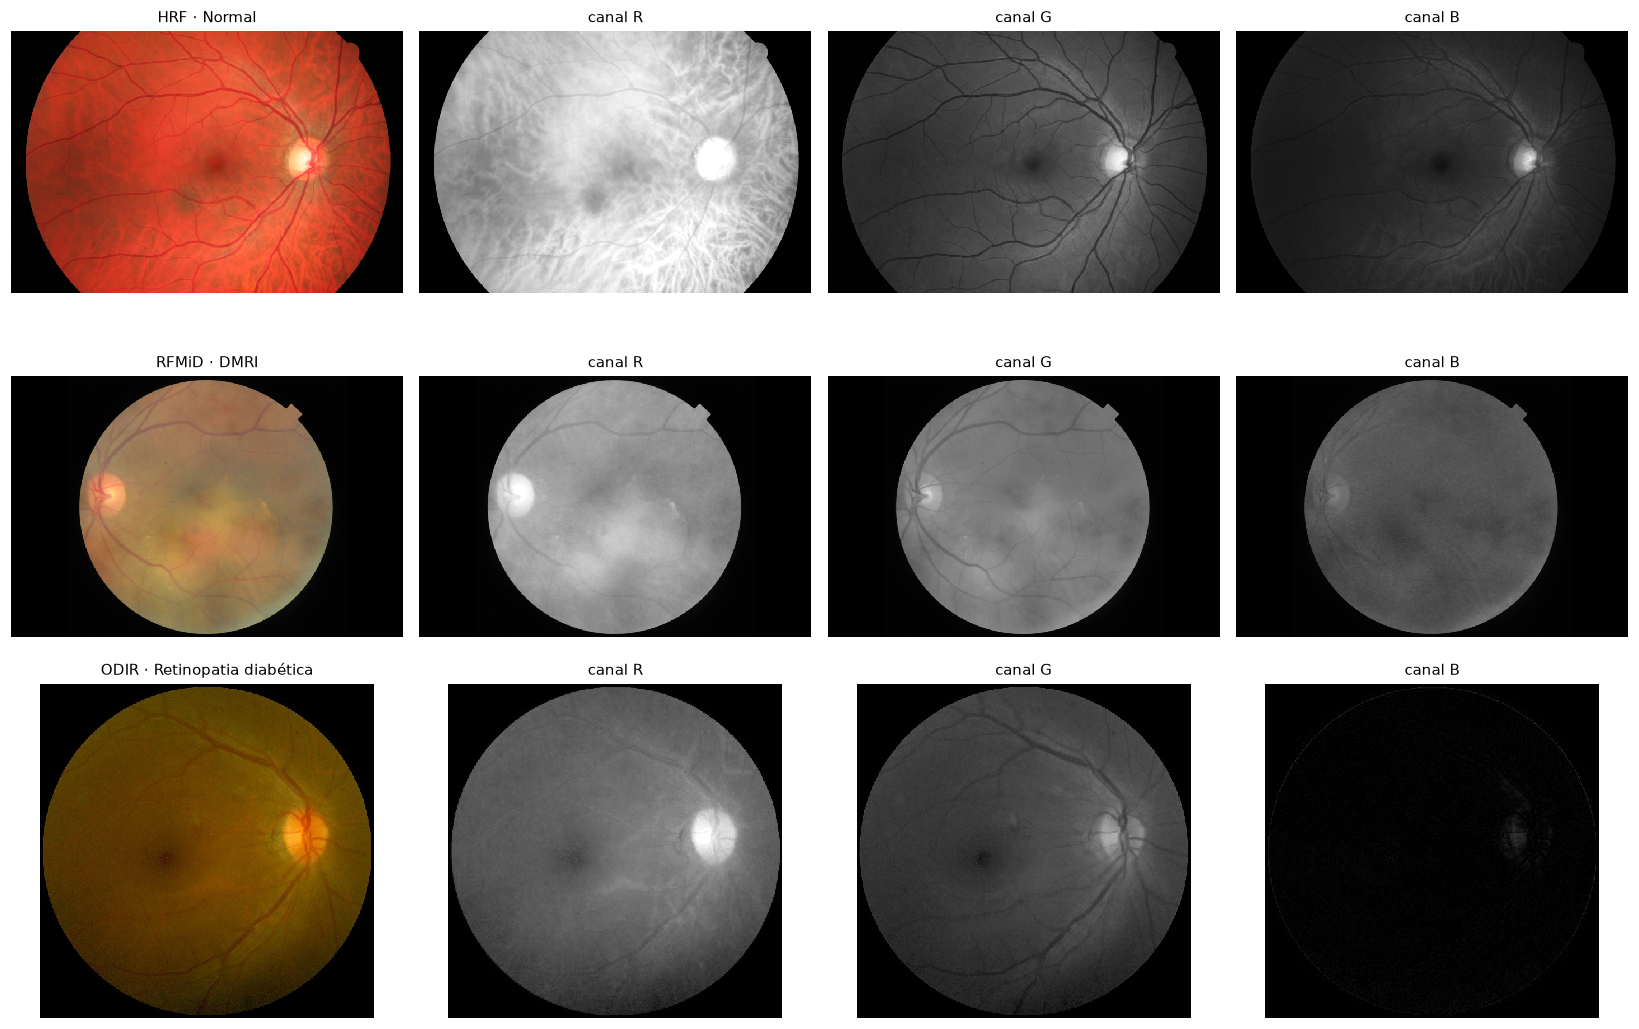

In [7]:
exemplos = [dados.selecionar("normal", "hrf").iloc[0], dados.selecionar("dmri", "rfmid").iloc[0], dados.selecionar("rd", "odir").iloc[0]]
fig, axs = plt.subplots(3, 4, figsize=(15, 9.6))
for i, r in enumerate(exemplos):
    im = dados.reduzir(dados.carregar_rgb(r.arquivo), 700)
    axs[i, 0].imshow(im); axs[i, 0].set_title(f"{r.fonte} · {dados.NOMES_CONDICAO[r.condicao]}")
    for k, nome in enumerate("RGB"):
        axs[i, k + 1].imshow(im[..., k], cmap="gray", vmin=0, vmax=255); axs[i, k + 1].set_title(f"canal {nome}")
    for a in axs[i]: a.axis("off")
fig.tight_layout(); V.salvar_figura(fig, "02_canais_rgb"); plt.show()

### Medindo o contraste dos vasos em cada canal

Impressão visual não basta. O HRF traz a **segmentação manual dos vasos** — então podemos medir, em 45 imagens, quão distinto é o valor de um pixel de vaso
em relação aos pixels vizinhos que *não* são vaso (um anel ao redor dos vasos). Usamos o **tamanho do efeito de Cohen (d)**:

$$ d = \frac{\mu_{\text{fundo}} - \mu_{\text{vaso}}}{\sqrt{(\sigma^2_{\text{fundo}} + \sigma^2_{\text{vaso}})/2}} $$

Quanto maior o *d*, mais separáveis são vaso e fundo naquele canal.

In [8]:
hrf = dados.carregar_hrf(1168)          # 45 imagens reduzidas + máscaras de vasos e FOV reamostradas
print(len(hrf), "imagens HRF carregadas;", hrf[0]["rgb"].shape)

def canais(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV); lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    return {"R": rgb[..., 0], "G": rgb[..., 1], "B": rgb[..., 2], "cinza": cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
            "V (HSV)": hsv[..., 2], "S (HSV)": hsv[..., 1], "L (LAB)": lab[..., 0], "a* (LAB)": lab[..., 1]}

def cohen_d(canal, vasos, fov):
    k = np.ones((3, 3), np.uint8)
    anel = cv2.dilate(vasos.astype(np.uint8), np.ones((21, 21), np.uint8)).astype(bool) & ~cv2.dilate(vasos.astype(np.uint8), k, iterations=3).astype(bool) & fov
    v, f = canal[vasos & fov].astype(np.float32), canal[anel].astype(np.float32)
    return (f.mean() - v.mean()) / np.sqrt((f.var() + v.var()) / 2)

registros = []
for it in hrf:
    for nome, c in canais(it["rgb"]).items():
        registros.append(dict(imagem=it["meta"].id, condicao=it["meta"].condicao, canal=nome, d=cohen_d(c, it["vasos"], it["fov"])))
df_d = pd.DataFrame(registros)
df_d["|d|"] = df_d.d.abs()
ordem = df_d.groupby("canal")["|d|"].median().sort_values(ascending=False).index      # ranking pelo tamanho do efeito
resumo = df_d.groupby("canal").agg(d_mediano=("d", "median"), abs_d_mediano=("|d|", "median"), d_min=("d", "min"), d_max=("d", "max")).loc[ordem].round(2)
resumo

45 imagens HRF carregadas; (779, 1168, 3)


,d_mediano,abs_d_mediano,d_min,d_max
canal,,,,
G,0.75,0.75,0.40,1.14
a* (LAB),-0.56,0.56,-1.49,-0.25
cinza,0.39,0.39,0.15,0.72
L (LAB),0.25,0.25,0.07,0.54
S (HSV),0.03,0.15,-0.60,0.35
B,0.03,0.12,-0.34,0.40
R,0.04,0.05,-0.12,0.35
V (HSV),0.04,0.05,-0.12,0.35


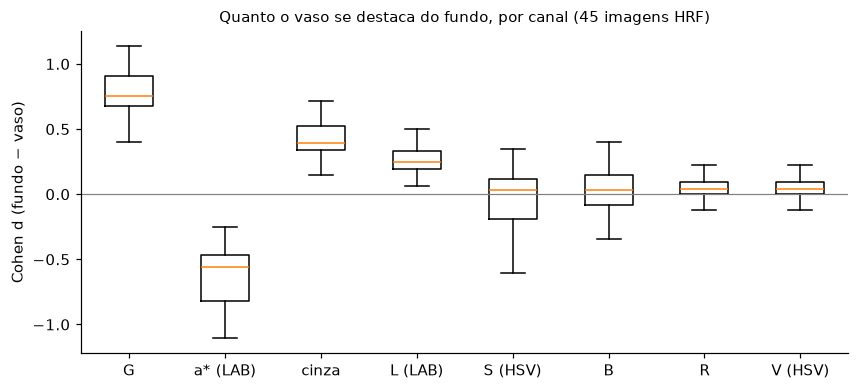

melhor canal (|d| mediano): G
d mediano por condição nos 3 melhores canais:
canal        G  a* (LAB)  cinza
condicao                       
glaucoma  0.75     -0.52   0.37
normal    0.69     -0.49   0.40
rd        0.89     -0.64   0.46


In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot([df_d[df_d.canal == c].d for c in ordem], showfliers=False)
ax.set_xticklabels(ordem)
ax.axhline(0, color="gray", lw=0.8); ax.set_ylabel("Cohen d (fundo − vaso)")
ax.set_title("Quanto o vaso se destaca do fundo, por canal (45 imagens HRF)")
plt.show()
print("melhor canal (|d| mediano):", ordem[0])
print("d mediano por condição nos 3 melhores canais:")
print(df_d.pivot_table(index="condicao", columns="canal", values="d", aggfunc="median").round(2)[list(ordem[:3])])

O **canal verde** domina com folga — é por isso que quase todo método clássico de retina começa nele. Em seguida vem o **a\*** do LAB, com *d* **negativo**:
nesse canal os vasos ficam *mais altos* (mais vermelhos) que o fundo, o sinal contrário do verde (onde ficam mais escuros). O **vermelho (R)**, o V e o azul têm *d* ≈ 0:
os vasos quase desaparecem contra a coroide iluminada. Cada canal enxerga uma estrutura — o vermelho é o melhor para o **disco óptico** e a coroide (exercício 1).

## 4. Espaços de cor: HSV, LAB e YCrCb

RGB mistura **brilho** e **cor** nos três canais. Outros espaços separam essas informações:

| Espaço | Canais | Uso típico em retina |
|---|---|---|
| **HSV** | matiz (H), saturação (S), valor/brilho (V) | S destaca regiões muito coloridas (exsudatos amarelos, hemorragias); V ≈ brilho |
| **LAB** | L (luminância), a* (verde↔vermelho), b* (azul↔amarelo) | **L é o canal ideal para CLAHE** (realça contraste sem mexer na cor); a* destaca vermelhos |
| **YCrCb** | Y (luma), Cr, Cb (diferenças de cor) | separação luma/croma — usado em codecs; alternativa ao LAB, mais rápida |

Em `uint8` a OpenCV usa faixas específicas: H em **0–179** (graus/2), S e V em 0–255, L em 0–255 (L·255/100) e a*/b* deslocados em **+128**.

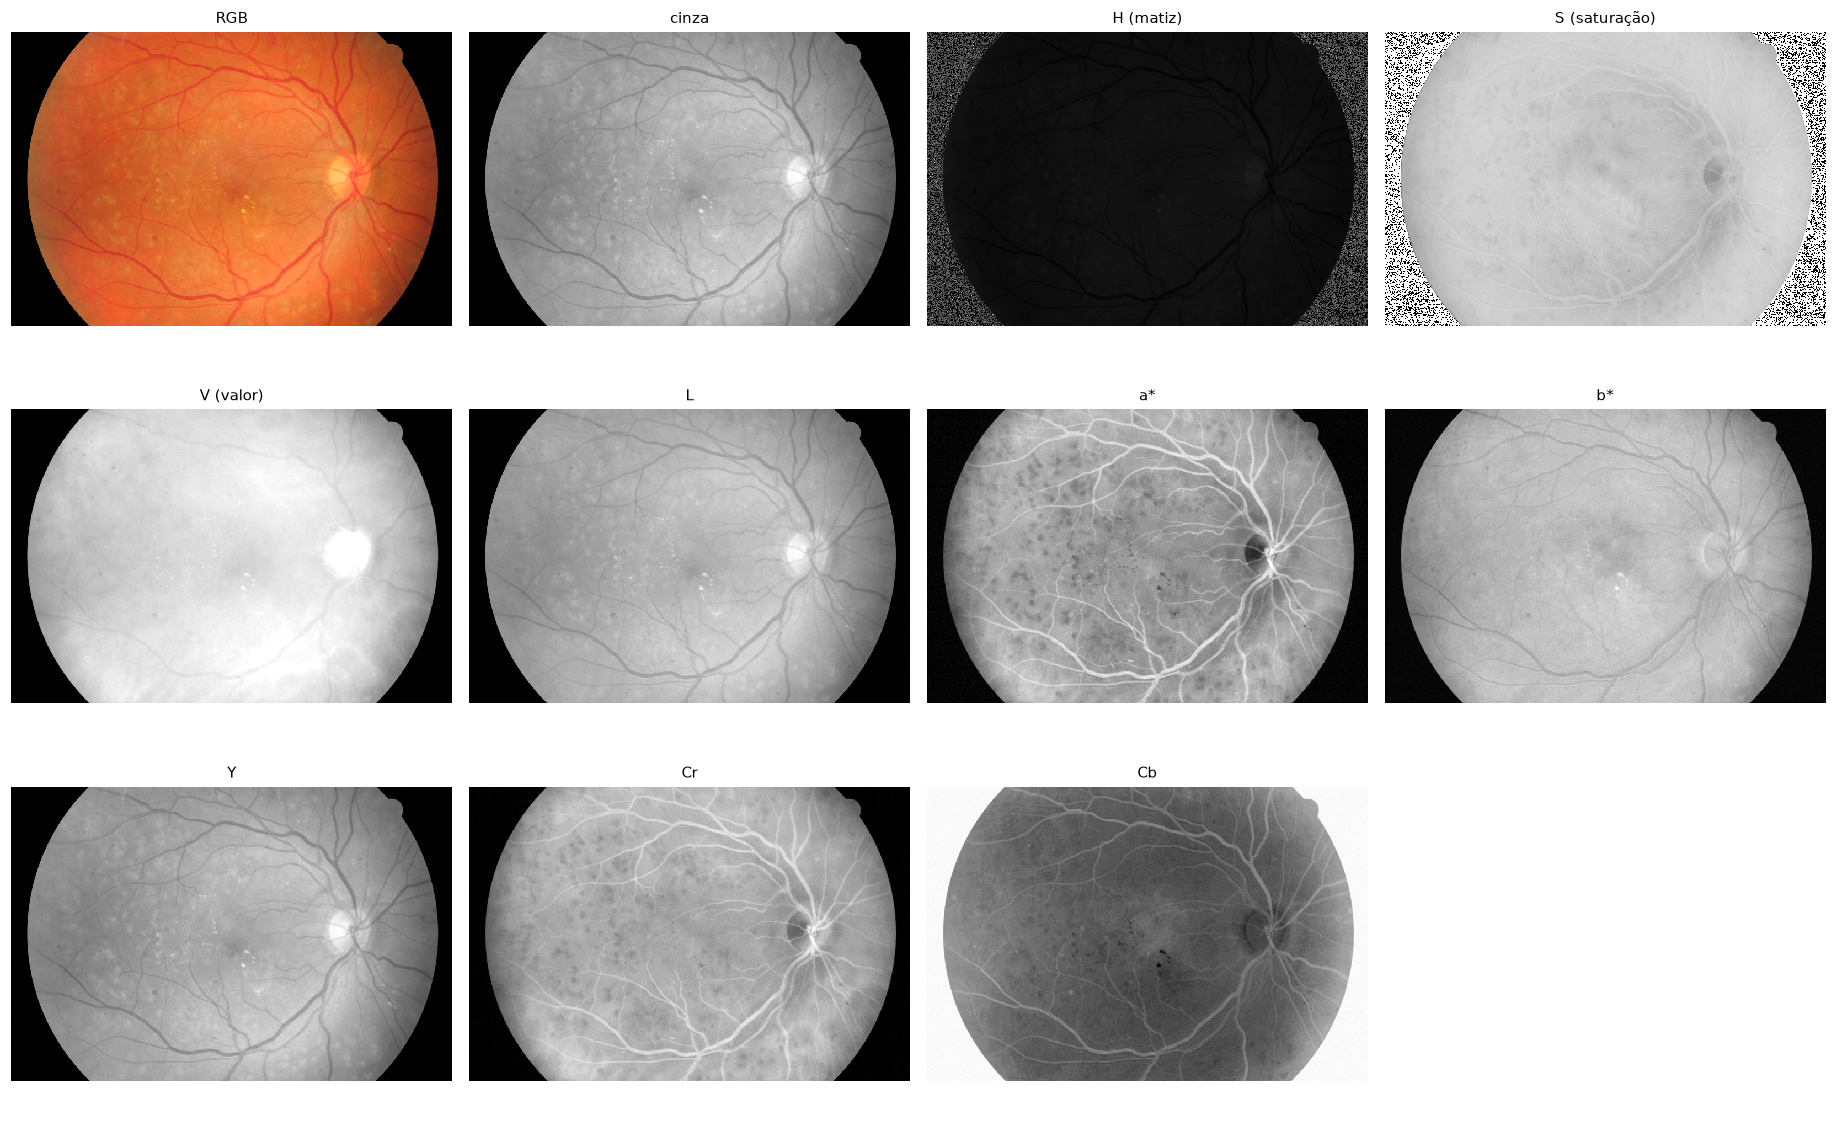

In [10]:
ex = dados.reduzir(dados.carregar_rgb(dados.selecionar("rd", "hrf").query("id == 'hrf_08_dr'").iloc[0].arquivo), 800)
hsv, lab, ycc = (cv2.cvtColor(ex, c) for c in (cv2.COLOR_RGB2HSV, cv2.COLOR_RGB2LAB, cv2.COLOR_RGB2YCrCb))
paineis = [("RGB", ex), ("cinza", cv2.cvtColor(ex, cv2.COLOR_RGB2GRAY)),
           ("H (matiz)", hsv[..., 0]), ("S (saturação)", hsv[..., 1]), ("V (valor)", hsv[..., 2]),
           ("L", lab[..., 0]), ("a*", lab[..., 1]), ("b*", lab[..., 2]),
           ("Y", ycc[..., 0]), ("Cr", ycc[..., 1]), ("Cb", ycc[..., 2])]
fig = V.grade([p[1] for p in paineis], [p[0] for p in paineis], colunas=4, largura=4.2)
V.salvar_figura(fig, "02_espacos_de_cor"); plt.show()

Observe: em **L**, **Y** e cinza os vasos são *escuros* e o disco óptico e os exsudatos são *claros*; em **a\*** e **Cr** acontece o **inverso** — vasos *brilhantes*, disco e exsudatos *escuros*.
O **V** satura no disco; o **H** é quase constante (a retina é toda avermelhada) e só mostra ruído fora do FOV. Isso sugere uma estratégia: *realçar contraste em L* (notebook 03) e usar
a\*/Cr como um segundo "olhar" sobre vasos e lesões (notebook 04).

In [11]:
# Reversibilidade: RGB → LAB → RGB preserva a imagem (erro de arredondamento de poucos níveis). RGB → cinza → RGB perde a cor para sempre.
ida_volta = cv2.cvtColor(cv2.cvtColor(ex, cv2.COLOR_RGB2LAB), cv2.COLOR_LAB2RGB)
cinza3 = cv2.cvtColor(cv2.cvtColor(ex, cv2.COLOR_RGB2GRAY), cv2.COLOR_GRAY2RGB)
print("RGB→LAB→RGB : erro máximo =", np.abs(ex.astype(int) - ida_volta).max(), "níveis")
print("RGB→cinza→RGB: erro médio  =", np.abs(ex.astype(int) - cinza3).mean().round(1), "níveis")

RGB→LAB→RGB : erro máximo = 4 níveis
RGB→cinza→RGB: erro médio  = 54.9 níveis


## 5. A cor depende da câmera (e isso importa para a IA)

Câmeras e iluminadores diferentes produzem retinas de **tons diferentes** — o HRF é bem vermelho, o RFMiD alaranjado escuro, o ODIR varia muito.
Calculamos a cor média (em LAB) dentro do FOV de cada imagem e olhamos como as imagens se agrupam:

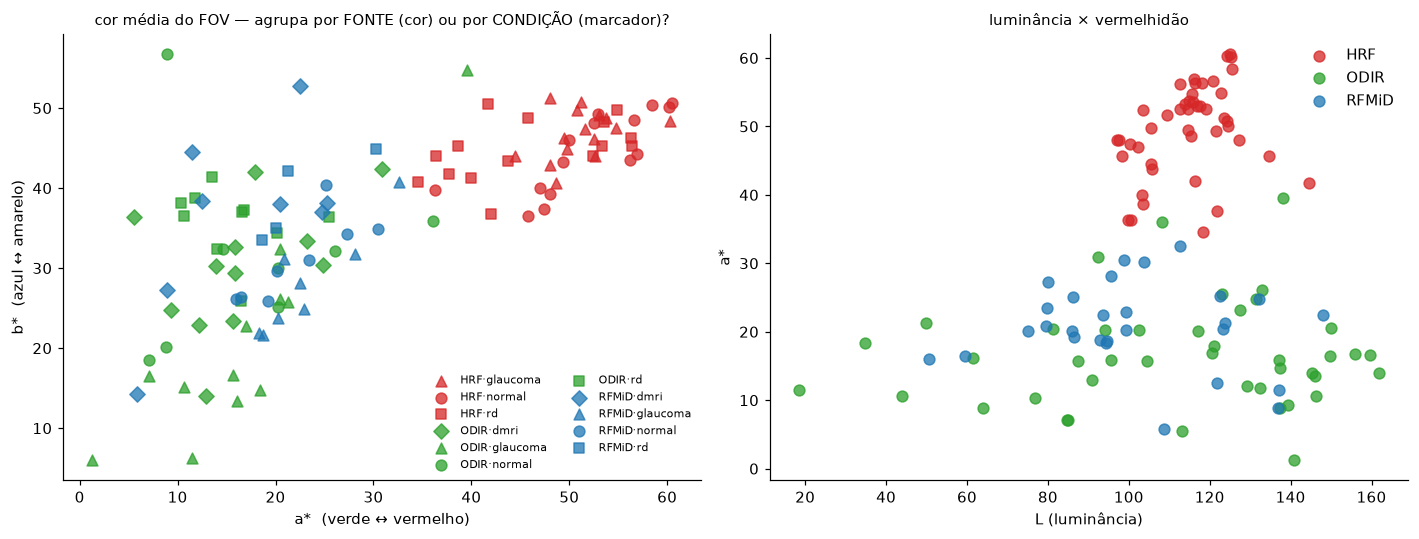

In [12]:
linhas = []
for _, r in dados.carregar_manifesto().iterrows():
    im = dados.reduzir(dados.carregar_rgb(r.arquivo), 256)
    fov = P.erodir_fov(P.mascara_fov(im), 6)
    lab_ = cv2.cvtColor(im, cv2.COLOR_RGB2LAB)
    linhas.append(dict(fonte=r.fonte, condicao=r.condicao, L=lab_[..., 0][fov].mean(), a=lab_[..., 1][fov].mean() - 128, b=lab_[..., 2][fov].mean() - 128))
cor = pd.DataFrame(linhas)

cores = {"HRF": "tab:red", "RFMiD": "tab:blue", "ODIR": "tab:green"}
marc = {"normal": "o", "rd": "s", "glaucoma": "^", "dmri": "D"}
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for (f, c), g in cor.groupby(["fonte", "condicao"]):
    axs[0].scatter(g.a, g.b, c=cores[f], marker=marc[c], s=50, alpha=0.75, label=f"{f}·{c}")
axs[0].set_xlabel("a*  (verde ↔ vermelho)"); axs[0].set_ylabel("b*  (azul ↔ amarelo)"); axs[0].set_title("cor média do FOV — agrupa por FONTE (cor) ou por CONDIÇÃO (marcador)?")
axs[0].legend(ncol=2, fontsize=7, frameon=False)
for f, g in cor.groupby("fonte"):
    axs[1].scatter(g.L, g.a, c=cores[f], s=50, alpha=0.75, label=f)
axs[1].set_xlabel("L (luminância)"); axs[1].set_ylabel("a*"); axs[1].legend(frameon=False); axs[1].set_title("luminância × vermelhidão")
fig.tight_layout(); V.salvar_figura(fig, "02_cor_por_camera"); plt.show()

In [13]:
# Quão fácil é adivinhar a FONTE (câmera) só pela cor média? E a CONDIÇÃO?
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = cor[["L", "a", "b"]].values
for alvo in ["fonte", "condicao"]:
    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
    pred = cross_val_predict(modelo, X, cor[alvo], cv=StratifiedKFold(5, shuffle=True, random_state=0))
    print(f"prever {alvo:9s} só pela cor média (L, a*, b*): acurácia balanceada = {balanced_accuracy_score(cor[alvo], pred):.2f}   (acaso ≈ {1/cor[alvo].nunique():.2f})")

prever fonte     só pela cor média (L, a*, b*): acurácia balanceada = 0.78   (acaso ≈ 0.33)
prever condicao  só pela cor média (L, a*, b*): acurácia balanceada = 0.39   (acaso ≈ 0.25)


A cor média identifica a **câmera** muito melhor do que a **doença**. Consequência prática: um modelo treinado com imagens de uma câmera pode aprender "atalhos" de cor
(*shortcut learning*) e falhar em outra. Por isso: (i) o pré-processamento deve **reduzir** diferenças de câmera (CLAHE em L, normalização por imagem — notebooks 03 e 06);
(ii) precisamos **validar no próprio retinógrafo**. *(Amostra pequena e fontes desbalanceadas por condição: veja isto como ilustração, não como prova.)*

## 6. Máscara do campo de visão (FOV) passo a passo

Toda retinografia tem uma moldura preta. Precisamos da máscara do **FOV** para: calcular estatísticas só na retina, evitar que a borda do círculo engane os filtros,
recortar a imagem e padronizar o tamanho. O HRF traz a máscara oficial — vamos construir a nossa e **comparar**.

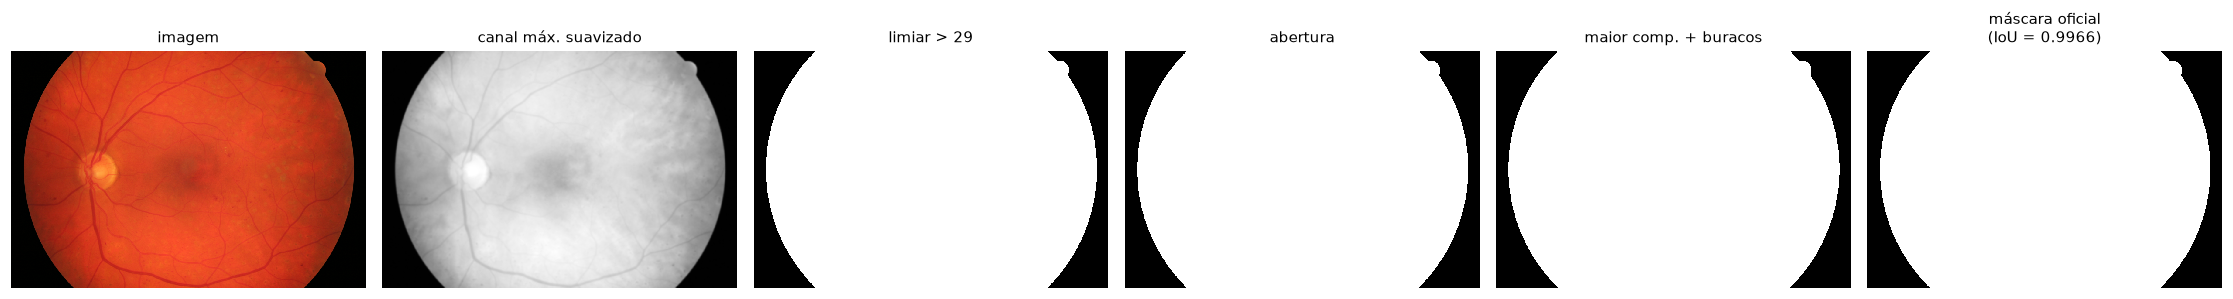

função do pacote → IoU = 0.9919


In [14]:
it = hrf[0]
im, fov_oficial = it["rgb"], it["fov"]

cinza = cv2.GaussianBlur(im.max(axis=2), (0, 0), 2)                                  # 1. canal máximo, suavizado
limiar = float(np.clip(0.12 * np.percentile(cinza, 99), 8, 30))                      # 2. limiar automático
binaria = (cinza > limiar).astype(np.uint8)
k = max(3, int(0.02 * min(binaria.shape)))
aberta = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))   # 3. abertura: remove marcas
n, rot, st, _ = cv2.connectedComponentsWithStats(aberta)
maior = rot == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])                                # 4. maior componente conexo
from scipy import ndimage as ndi
final = ndi.binary_fill_holes(maior)                                                  # 5. preenche buracos

iou = (final & fov_oficial).sum() / (final | fov_oficial).sum()
V.grade([im, cinza, binaria, aberta, final, fov_oficial],
        ["imagem", "canal máx. suavizado", f"limiar > {limiar:.0f}", "abertura", "maior comp. + buracos", f"máscara oficial\n(IoU = {iou:.4f})"], colunas=6, largura=3.4)
plt.show()
print("função do pacote → IoU =", round(float((P.mascara_fov(im) & fov_oficial).sum() / (P.mascara_fov(im) | fov_oficial).sum()), 4))

**E se o limiar estiver errado?** Numa imagem escura do ODIR, um limiar fixo alto "come" a retina; um baixo inclui ruído da moldura:

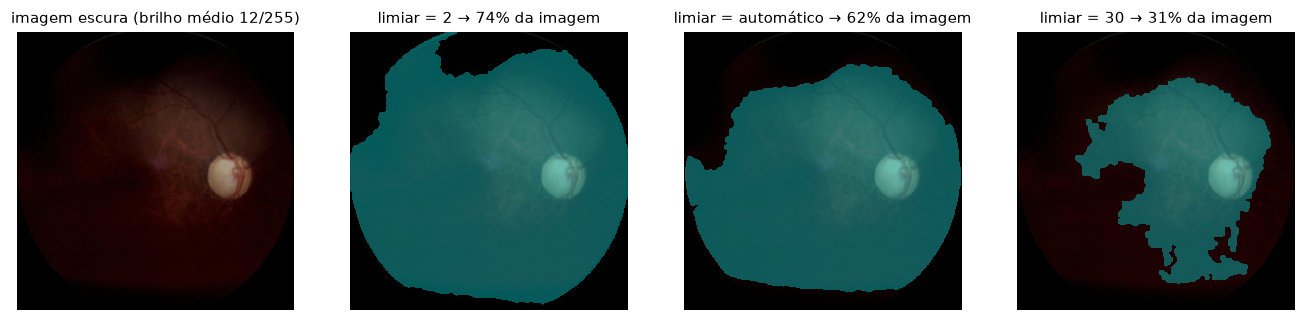

In [15]:
escura = dados.carregar_rgb(dados.carregar_manifesto().query("id == 'odir_glaucoma_08'").iloc[0].arquivo)   # captura muito subexposta
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
axs[0].imshow(escura); axs[0].set_title(f"imagem escura (brilho médio {escura.mean():.0f}/255)")
for ax, lim in zip(axs[1:], [2, None, 30]):
    m_ = P.mascara_fov(escura, limiar=lim)
    ax.imshow(V.sobrepor(escura, m_, (0, 255, 255), 0.35)); ax.set_title(f"limiar = {'automático' if lim is None else lim} → {100*m_.mean():.0f}% da imagem")
for a in axs: a.axis("off")
plt.show()

Um limiar **fixo** alto (30) deixa só ~30 % da imagem; um muito baixo (2) começa a incluir ruído da moldura. O limiar **relativo** (12 % do percentil 99, com piso 8 e teto 30) se adapta à exposição e fica no meio-termo — ainda perde um pouco das bordas mais escuras, por isso o notebook 05 sinaliza essa captura como *subexposta*.

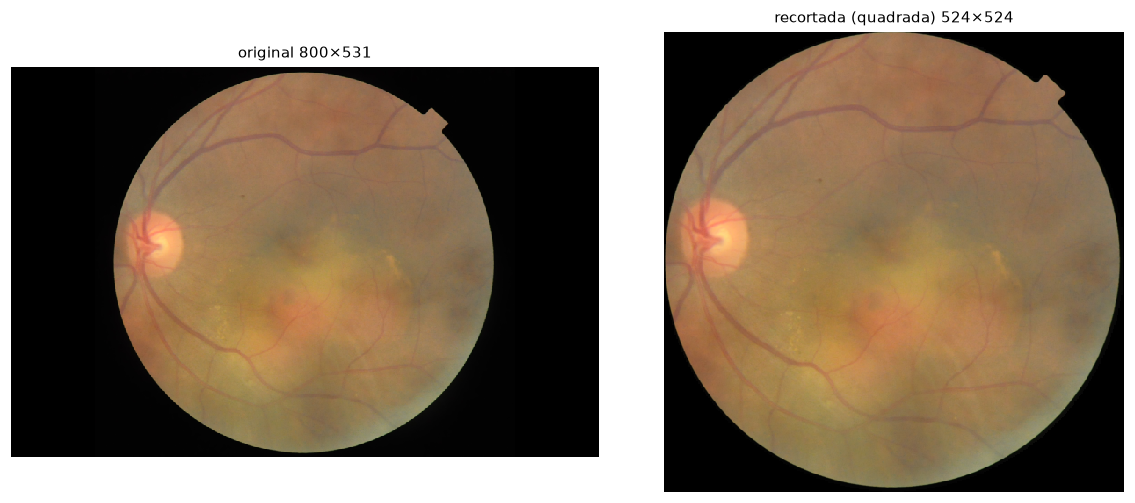

In [16]:
# Recorte no FOV + padding quadrado (usado no notebook 06 antes de redimensionar para o modelo)
im2 = dados.reduzir(dados.carregar_rgb(dados.selecionar("dmri", "rfmid").iloc[0].arquivo), 800)
rec, m_rec = P.recortar_fov(im2)
V.grade([im2, rec], [f"original {im2.shape[1]}×{im2.shape[0]}", f"recortada (quadrada) {rec.shape[1]}×{rec.shape[0]}"], colunas=2, largura=5.5)
plt.show()

## Exercícios propostos

1. **Outro canal, outra estrutura.** Repita a medida de Cohen *d* para o **disco óptico** (use `P.localizar_disco_optico` como máscara) contra o anel ao redor.
   Qual canal o separa melhor do fundo? Isso contradiz ou complementa o resultado dos vasos?
2. **HSV para lesões amarelas.** Em imagens de RD com exsudatos (HRF 06, 08), limiarize o canal **S** ou **b\*** e mostre a máscara sobre a imagem. Quantos "candidatos" surgem em uma imagem *saudável*?
3. **Interpolação.** Amplie a imagem 4× com `NEAREST`, `LINEAR`, `CUBIC` e `LANCZOS4`. Meça o tempo e o SSIM (contra a original reduzida e depois ampliada). Vale a pena o `LANCZOS4`?
4. **Atalho de cor.** Repita a análise da seção 5 *removendo* a diferença entre câmeras: subtraia da cor de cada imagem a média da sua fonte. O que acontece com a acurácia de prever a condição?
5. **FOV robusto.** Encontre (ou crie, escurecendo/borrando) uma imagem em que `mascara_fov` falhe. Que parâmetro você mudaria e por quê?